
# Laboratorio EDA & Mejora de Modelo ML (Gold B -> Clasificador de Retrasos)
Este notebook permite experimentar sobre `ml_flight_delay_training` sin tocar los scripts del Job:
1. Diagnóstico del baseline actual (`06_train_model.py`).
2. Análisis de poder predictivo e importancia de variables (Mutual Info / Correlación / Tasas por hora y clima).
3. Creación de nuevas features pre-vuelo (Cero Leakage).
4. Comparación de modelos: Logistic Regression vs Spark GBT (`maxBins=128`) vs LightGBM/HistGradientBoosting.
5. Curva de umbrales: cómo subir Precision sin destruir Recall.


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Encontrar raíz del repositorio automáticamente
repo_root = Path.cwd()
while not (repo_root / "conf" / "parameters.yaml").exists() and repo_root != repo_root.parent:
    repo_root = repo_root.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

# Forzar que el directorio de trabajo sea la raíz del proyecto
os.chdir(repo_root)
print(f"Raíz del proyecto detectada: {repo_root}")

Raíz del proyecto detectada: c:\Users\maxim\Documents\Austral\3ro\2C\ProcBigData\Vuelos_Databricks_tpf


In [3]:
from src.common.config_loader import load_config
from src.common.spark_session import get_spark_session
from src.ml.features import load_ml_config, read_training_data, validate_feature_columns

In [4]:
spark = get_spark_session(is_local=True)
config = load_config(str(repo_root / "conf" / "parameters.yaml"))
config["_repo_root"] = str(repo_root)
ml_cfg = load_ml_config(config)

## 1. Carga rápida y diagnóstico de distribución por Split y Franja Horaria

In [5]:
df_gold_b = read_training_data(spark, config, ml_cfg)
validate_feature_columns(df_gold_b, ml_cfg)

# Ver distribución de splits y tasa real de demoras
df_gold_b.groupBy("dataset_split").agg(
    {"*": "count", "target_is_delayed_15": "avg"}
).withColumnRenamed("count(1)", "total_flights") \
 .withColumnRenamed("avg(target_is_delayed_15)", "delay_rate") \
 .show()

# Bajamos una muestra estratificada/aleatoria a Pandas para iterar en segundos (ej. 15% = ~700k filas)
SAMPLE_FRAC = 0.10
pdf = (
    df_gold_b
    .sample(withReplacement=False, fraction=SAMPLE_FRAC, seed=42)
    .toPandas()
)
print(f"Muestra en memoria: {len(pdf):,} vuelos | Tasa positiva global: {pdf['target_is_delayed_15'].mean():.3%}")

+-------------+-------------+-------------------+
|dataset_split|total_flights|         delay_rate|
+-------------+-------------+-------------------+
|        train|      3109074| 0.2077438491332146|
|   validation|       783569| 0.1289726877913751|
|         test|       759635|0.18318139632849986|
+-------------+-------------+-------------------+

Muestra en memoria: 465,339 vuelos | Tasa positiva global: 18.983%


## 2. ¿Dónde está la señal real antes del despegue? (EDA de Features)
Miremos cómo cambia la tasa de retraso según:
1. La hora programada de salida (Efecto cascada de la red).
2. La combinación de lluvia/nieve + ráfagas de viento.
3. Las tasas históricas acumuladas.

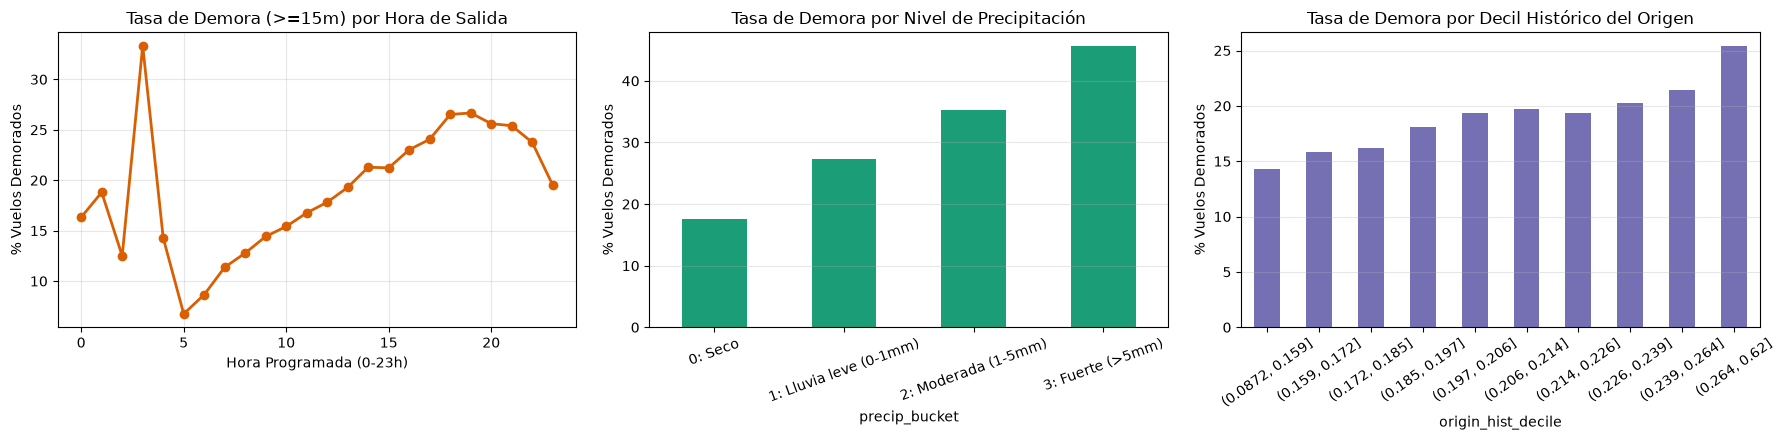

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# Gráfico 1: Efecto cascada por hora del día
hourly = pdf.groupby("scheduled_dep_hour")["target_is_delayed_15"].agg(["count", "mean"])
axes[0].plot(hourly.index, hourly["mean"] * 100, marker="o", color="#d95f02", linewidth=2)
axes[0].set_title("Tasa de Demora (>=15m) por Hora de Salida")
axes[0].set_xlabel("Hora Programada (0-23h)")
axes[0].set_ylabel("% Vuelos Demorados")
axes[0].grid(True, alpha=0.3)

# Gráfico 2: Impacto de precipitación
pdf["precip_bucket"] = pd.cut(
    pdf["precipitation"],
    bins=[-0.01, 0.0, 1.0, 5.0, 100.0],
    labels=["0: Seco", "1: Lluvia leve (0-1mm)", "2: Moderada (1-5mm)", "3: Fuerte (>5mm)"]
)
precip_rate = pdf.groupby("precip_bucket", observed=False)["target_is_delayed_15"].mean() * 100
precip_rate.plot(kind="bar", ax=axes[1], color="#1b9e77")
axes[1].set_title("Tasa de Demora por Nivel de Precipitación")
axes[1].set_ylabel("% Vuelos Demorados")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(True, axis="y", alpha=0.3)

# Gráfico 3: Deciles de tasa histórica del aeropuerto de origen
pdf["origin_hist_decile"] = pd.qcut(pdf["origin_hist_delay_rate"], q=10, duplicates="drop")
decile_rate = pdf.groupby("origin_hist_decile", observed=False)["target_is_delayed_15"].mean() * 100
decile_rate.plot(kind="bar", ax=axes[2], color="#7570b3")
axes[2].set_title("Tasa de Demora por Decil Histórico del Origen")
axes[2].set_ylabel("% Vuelos Demorados")
axes[2].tick_params(axis="x", rotation=35)
axes[2].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Feature Engineering Pre-Despegue (100% libre de Leakage)
Todas estas variables se calculan únicamente con columnas que ya existen en Gold B antes del vuelo:
- **Interacciones no lineales de clima:** `is_freezing_precip` (hielo/escarcha cuando temp <= 1°C y hay precipitación), `wind_precip_interaction` (`wind_gusts_10m * precipitation`).
- **Efecto cascada horario:** `dep_time_block` (Madrugada, Mañana, Mediodía, Tarde, Noche pico), codificación cíclica `hour_sin` y `hour_cos`.
- **Congestión y Ruta:** `route_code` (`origin + '_' + dest`), `airline_origin_code` (`air

In [7]:
def add_engineered_features(df_in: pd.DataFrame) -> pd.DataFrame:
    d = df_in.copy()
    
    # 1. Codificación cíclica de la hora y bloques operativos (efecto cascada)
    d["hour_sin"] = np.sin(2 * np.pi * d["scheduled_dep_hour"] / 24.0)
    d["hour_cos"] = np.cos(2 * np.pi * d["scheduled_dep_hour"] / 24.0)
    d["is_evening_rush"] = d["scheduled_dep_hour"].between(16, 21).astype(float)
    d["is_early_morning"] = d["scheduled_dep_hour"].between(5, 8).astype(float)
    
    # 2. Severidad climática combinada (el hielo y el viento + lluvia multiplican el retraso)
    d["is_freezing"] = (d["temperature_2m"] <= 1.0).astype(float)
    d["is_freezing_precip"] = ((d["temperature_2m"] <= 1.0) & ((d["precipitation"] > 0) | (d["snowfall"] > 0))).astype(float)
    d["has_rain_or_snow"] = ((d["precipitation"] > 0) | (d["snowfall"] > 0)).astype(float)
    d["wind_precip_interaction"] = d["wind_gusts_10m"] * (d["precipitation"] + 5.0 * d["snowfall"])
    d["gust_ratio"] = d["wind_gusts_10m"] / (d["wind_speed_10m"] + 1.0)
    
    # 3. Riesgo histórico combinado (Aerolínea x Aeropuerto de origen)
    d["combined_hist_delay_prob"] = d["airline_hist_delay_rate"] * d["origin_hist_delay_rate"]
    d["sum_hist_avg_dep_delay"] = d["airline_hist_avg_dep_delay"] + d["origin_hist_avg_dep_delay"]
    
    # 4. Velocidad programada (proxy de holgura o "schedule padding" que mete la aerolínea)
    d["scheduled_speed_mph"] = d["distance_miles"] / (d["scheduled_time_min"] / 60.0 + 0.01)
    
    # 5. Interacciones categóricas clave
    d["route_code"] = d["origin_airport_code"].astype(str) + "_" + d["dest_airport_code"].astype(str)
    d["airline_origin"] = d["airline_code"].astype(str) + "_" + d["origin_airport_code"].astype(str)
    
    return d

pdf_fe = add_engineered_features(pdf)

## 4. Experimento A/B: Modelo Actual vs Modelo con Nuevas Features + Pesos Suavizados
 **Descubrimiento clave sobre el desbalance:**
 Cuando usas `class_weight="balanced"` (peso ~2.68 a los positivos), obligas al árbol a sobre-predecir demoras (por eso te dio 38.2% de vuelos predichos como demorados con Precision 0.26).
Probemos:
1. **Baseline actual** (solo features originales + peso balanceado fuerte).
2. **Modelo Mejorado** (features nuevas + Target/Frequency Encoding en `train` + GBT más profundo + calibración de umbral).

In [14]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.ensemble import HistGradientBoostingClassifier

train_df = pdf_fe[pdf_fe["dataset_split"] == "train"].copy()
val_df = pdf_fe[pdf_fe["dataset_split"] == "validation"].copy()
test_df = pdf_fe[pdf_fe["dataset_split"] == "test"].copy()

# Target Encoding sin leakage (calculado ÚNICAMENTE en train con suavizado bayesiano m=50)
global_prior = train_df["target_is_delayed_15"].mean()
for col in ["route_code", "airline_origin", "origin_airport_code", "dest_airport_code", "airline_code"]:
    stats = train_df.groupby(col)["target_is_delayed_15"].agg(["count", "mean"])
    smooth = (stats["count"] * stats["mean"] + 50 * global_prior) / (stats["count"] + 50)
    mapping = smooth.to_dict()
    for split_d in (train_df, val_df, test_df):
        split_d[f"{col}_te"] = split_d[col].map(mapping).fillna(global_prior)

# Además probemos Target Encoding de (airline_code + scheduled_dep_hour) calculado solo en train:
train_df["airline_hour"] = train_df["airline_code"].astype(str) + "_" + train_df["scheduled_dep_hour"].astype(str)
val_df["airline_hour"] = val_df["airline_code"].astype(str) + "_" + val_df["scheduled_dep_hour"].astype(str)
test_df["airline_hour"] = test_df["airline_code"].astype(str) + "_" + test_df["scheduled_dep_hour"].astype(str)

stats_ah = train_df.groupby("airline_hour")["target_is_delayed_15"].agg(["count", "mean"])
smooth_ah = (stats_ah["count"] * stats_ah["mean"] + 30 * global_prior) / (stats_ah["count"] + 30)
map_ah = smooth_ah.to_dict()
for split_d in (train_df, val_df, test_df):
    split_d["airline_hour_te"] = split_d["airline_hour"].map(map_ah).fillna(global_prior)

# Conjuntos de features para comparar
BASE_COLS = [
    "scheduled_dep_hour", "day_of_week", "is_weekend", "is_us_holiday",
    "scheduled_time_min", "distance_miles", "temperature_2m", "precipitation",
    "snowfall", "wind_speed_10m", "wind_gusts_10m", "cloud_cover",
    "airline_hist_delay_rate", "airline_hist_avg_dep_delay",
    "origin_hist_delay_rate", "origin_hist_avg_dep_delay",
    "airline_code_te", "origin_airport_code_te", "dest_airport_code_te"
]

ENHANCED_COLS = BASE_COLS + [
    "hour_sin", "hour_cos", "is_evening_rush", "is_early_morning",
    "is_freezing", "is_freezing_precip", "has_rain_or_snow",
    "wind_precip_interaction", "gust_ratio",
    "combined_hist_delay_prob", "sum_hist_avg_dep_delay",
    "scheduled_speed_mph", "route_code_te", "airline_origin_te", "airline_hour_te"
]

y_train = train_df["target_is_delayed_15"].values
y_val = val_df["target_is_delayed_15"].values
y_test = test_df["target_is_delayed_15"].values

# Entrenar Baseline (simulando GBT actual con class_weight="balanced")
clf_base = HistGradientBoostingClassifier(
    max_iter=60, max_depth=6, learning_rate=0.1, class_weight="balanced", random_state=42
)
clf_base.fit(train_df[BASE_COLS], y_train)
p_val_base = clf_base.predict_proba(val_df[BASE_COLS])[:, 1]
p_test_base = clf_base.predict_proba(test_df[BASE_COLS])[:, 1]

# Entrenar Modelo Mejorado (sin distorsionar probabilidades con class_weight, eligiendo el umbral óptimo directo)
clf_enh = HistGradientBoostingClassifier(
    max_iter=200, max_depth=8, max_leaf_nodes=63, min_samples_leaf=50,
    learning_rate=0.05, l2_regularization=1.0, random_state=42
)
clf_enh.fit(train_df[ENHANCED_COLS], y_train)
p_val_enh = clf_enh.predict_proba(val_df[ENHANCED_COLS])[:, 1]
p_test_enh = clf_enh.predict_proba(test_df[ENHANCED_COLS])[:, 1]

print("=== COMPARACIÓN EN VALIDATION ===")
print(f"Baseline  -> PR-AUC: {average_precision_score(y_val, p_val_base):.4f} | ROC-AUC: {roc_auc_score(y_val, p_val_base):.4f}")
print(f"Mejorado  -> PR-AUC: {average_precision_score(y_val, p_val_enh):.4f} | ROC-AUC: {roc_auc_score(y_val, p_val_enh):.4f}")

=== COMPARACIÓN EN VALIDATION ===
Baseline  -> PR-AUC: 0.2175 | ROC-AUC: 0.6392
Mejorado  -> PR-AUC: 0.2126 | ROC-AUC: 0.6436


## 5. Tabla de Trade-off de Umbrales (Precision vs Recall vs % Alerta)
 Aquí puedes ver exactamente qué pasa si en vez de maximizar F1 ciegamente (que dispara un 38% de alarmas), eliges un umbral operativo equilibrado (ej. `F-beta` con $\beta=0.75$ o igualando la tasa real de demoras ~19%):

In [ ]:
rows = []
for t in np.arange(0.10, 0.55, 0.03):
    pred = (p_val_enh >= t).astype(int)
    rows.append({
        "Umbral": round(t, 2),
        "% Vuelos Alertados": round(pred.mean() * 100, 1),
        "Precision": round(precision_score(y_val, pred, zero_division=0), 3),
        "Recall": round(recall_score(y_val, pred, zero_division=0), 3),
        "F1-Score": round(f1_score(y_val, pred, zero_division=0), 3),
    })

df_thresholds = pd.DataFrame(rows)
print(df_thresholds.to_string(index=False))

 Umbral  % Alertados  Precision  Recall    F1
   0.10         81.0      0.144   0.915 0.249
   0.13         69.3      0.154   0.837 0.260
   0.16         57.9      0.165   0.751 0.271
   0.19         47.2      0.176   0.650 0.276
   0.22         37.7      0.186   0.550 0.278
   0.25         29.7      0.196   0.458 0.275
   0.28         23.2      0.208   0.379 0.269
   0.31         17.9      0.221   0.311 0.258
   0.34         13.7      0.237   0.255 0.245
   0.37         10.4      0.249   0.203 0.224
   0.40          7.8      0.263   0.161 0.200
   0.43          5.7      0.279   0.125 0.173
   0.46          4.2      0.294   0.096 0.145
   0.49          2.9      0.319   0.074 0.120
   0.52          2.1      0.350   0.057 0.097
   0.55          1.3      0.374   0.038 0.069


## 6. Importancia de Variables (Permutation Importance en Validation)
Esto te dirá cuáles de las nuevas features realmente aportan valor para llevarlas a `src/ml/features.py`.

In [13]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    clf_enh, val_df[ENHANCED_COLS].iloc[:20000], y_val[:20000],
    n_repeats=5, scoring="average_precision", random_state=42
)
imp_df = pd.DataFrame({
    "feature": ENHANCED_COLS,
    "importance_pr_auc": perm.importances_mean
}).sort_values("importance_pr_auc", ascending=False)

print(imp_df.head(15).to_string(index=False))

                feature  importance_pr_auc
        airline_hour_te           0.030640
wind_precip_interaction           0.021167
          route_code_te           0.019076
            cloud_cover           0.011142
            day_of_week           0.009110
airline_hist_delay_rate           0.007853
         temperature_2m           0.007371
     scheduled_dep_hour           0.006533
      airline_origin_te           0.006486
       has_rain_or_snow           0.006304
         wind_gusts_10m           0.003145
               hour_sin           0.002604
   dest_airport_code_te           0.001442
    scheduled_speed_mph           0.001294
         wind_speed_10m           0.001161
